# Travelling Salesman Problem via Column Generation

## Overview

We reformulate TSP as a **Set Partitioning Problem (SPP)** and solve its LP relaxation via column generation.

### Formulation

Let $\mathcal{R}$ be the set of all possible subtours (cycles visiting a subset of cities $S_r \subseteq V$).

$$
\begin{aligned}
\min \quad & \sum_{r \in \mathcal{R}} c_r \, \lambda_r \\
\text{s.t.} \quad & \sum_{r \in \mathcal{R}} a_{ir} \, \lambda_r = 1 & \forall\, i \in V \quad [\pi_i] \\
& \lambda_r \geq 0 & \forall\, r \in \mathcal{R}
\end{aligned}
$$

where $a_{ir} = 1$ if city $i \in S_r$, and $c_r$ is the minimum-cost Hamiltonian cycle over $S_r$.

### Column Generation

| Step | What happens |
|------|--------------|
| **Restricted Master Problem (RMP)** | Solve LP with current columns; get duals $\pi$ |
| **Pricing Problem** | Find subtour $r^*$ with min reduced cost $\bar{c}_r = c_r - \sum_{i \in S_r} \pi_i$ |
| **Stopping criterion** | If $\bar{c}_{r^*} \geq -\varepsilon$, LP is optimal |
| **Column addition** | Otherwise add $r^*$ to RMP and repeat |

The pricing subproblem — *find the subtour with most negative reduced cost* — is solved efficiently here using **Held-Karp dynamic programming** over all subsets.

In [18]:
# ── Dependencies ─────────────────────────────────────────────────────────────
# pip install pyomo highspy numpy matplotlib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as mpatches
from itertools import combinations
import math, time, warnings
warnings.filterwarnings('ignore')

import pyomo.environ as pyo

try:
    import highspy
except ImportError:
    raise ImportError("Install highspy:  pip install highspy")

try:
    solver_test = pyo.SolverFactory('appsi_highs')
    print(f"Pyomo appsi_highs solver available: {solver_test.available()}")
except Exception as e:
    raise ImportError(f"Pyomo appsi_highs not available: {e}")


Pyomo appsi_highs solver available: True


## 1. Problem Instance

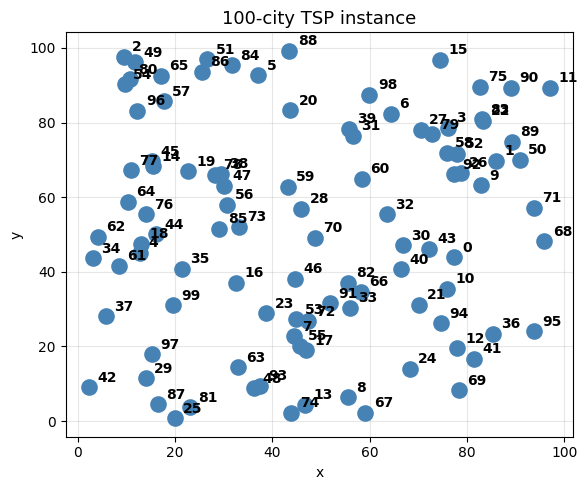

Cities: 100   |   Distance matrix shape: (100, 100)


In [19]:
# ── Generate a medium TSP instance ───────────────────────────────────────────
rng = np.random.default_rng(seed=42)
N = 100                                         # number of cities
coords = rng.uniform(0, 100, size=(N, 2))       # (x, y) coordinates

# Euclidean distance matrix
def euclidean_distance_matrix(coords):
    diff = coords[:, None, :] - coords[None, :, :]
    return np.sqrt((diff ** 2).sum(-1))

D = euclidean_distance_matrix(coords)           # D[i,j] = distance from i to j
np.fill_diagonal(D, np.inf)                     # no self-loops

# ── Visualise cities ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(coords[:, 0], coords[:, 1], s=120, zorder=3, color='steelblue')
for i, (x, y) in enumerate(coords):
    ax.annotate(str(i), (x, y), textcoords='offset points', xytext=(6, 4), fontsize=10, fontweight='bold')
ax.set_title(f"{N}-city TSP instance", fontsize=13)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('cities.png', dpi=120)
plt.show()
print(f"Cities: {N}   |   Distance matrix shape: {D.shape}")

## 2. Subrouting Primitives

A *subtour* over a subset $S$ is the minimum-cost Hamiltonian cycle visiting the cities in $S$.  
We compute it using **Held-Karp DP** in $O(|S|^2 \cdot 2^{|S|})$ time.

In [20]:
# ── Held-Karp DP for TSP on an arbitrary subset of cities ────────────────────

def held_karp_subset(cities: list[int], D: np.ndarray) -> tuple[float, list[int]]:
    """
    Solve TSP on `cities` (a list of city indices) using Held-Karp DP.
    Returns (min_cost, best_tour_as_list_of_city_indices).
    The tour starts and ends at cities[0] (arbitrary; result is a cycle).
    """
    k = len(cities)
    if k == 1:
        return 0.0, cities                             # trivial single-city 'loop'
    if k == 2:
        i, j = cities
        cost = D[i, j] + D[j, i] if not np.isinf(D[i,j]) else np.inf
        return cost, [i, j]

    # Map local indices 0..k-1  ↔  global city labels
    c2l = {c: l for l, c in enumerate(cities)}        # city → local idx
    d   = np.full((k, k), np.inf)
    for a in range(k):
        for b in range(k):
            if a != b:
                d[a, b] = D[cities[a], cities[b]]

    INF  = float('inf')
    FULL = (1 << k) - 1
    # dp[mask][v] = min cost to reach local city v having visited exactly the
    #               cities encoded in mask, starting from city 0
    dp   = [[INF] * k for _ in range(1 << k)]
    parent = [[-1] * k for _ in range(1 << k)]

    dp[1][0] = 0.0                                   # start at local city 0

    for mask in range(1 << k):
        for u in range(k):
            if dp[mask][u] == INF:
                continue
            if not (mask >> u) & 1:
                continue
            for v in range(k):
                if (mask >> v) & 1:
                    continue
                new_mask = mask | (1 << v)
                new_cost = dp[mask][u] + d[u, v]
                if new_cost < dp[new_mask][v]:
                    dp[new_mask][v] = new_cost
                    parent[new_mask][v] = u

    # Close the tour (return to city 0)
    best_cost = INF
    last      = -1
    for u in range(1, k):
        if dp[FULL][u] + d[u][0] < best_cost:
            best_cost = dp[FULL][u] + d[u][0]
            last      = u

    # Reconstruct tour
    tour_local = []
    mask, node = FULL, last
    while node != -1:
        tour_local.append(node)
        prev = parent[mask][node]
        mask ^= (1 << node)
        node  = prev
    tour_local.reverse()
    tour = [cities[l] for l in tour_local]
    return best_cost, tour


def subtour_cost(subset: frozenset, D: np.ndarray) -> tuple[float, list[int]]:
    """Return (min_cost, optimal_route) for a Hamiltonian cycle over `subset`."""
    cities = sorted(subset)
    return held_karp_subset(cities, D)


# Quick sanity check
test_s = frozenset([0, 3, 7, 9])
tc, tr = subtour_cost(test_s, D)
print(f"Subtour over {sorted(test_s)}:  cost = {tc:.2f},  route = {tr}")

Subtour over [0, 3, 7, 9]:  cost = 140.36,  route = [0, 9, 3, 7]


## 3. Column (Subtour) Representation

In [21]:
from dataclasses import dataclass, field

@dataclass
class Column:
    """A subtour (cycle) visiting a subset of cities."""
    subset : frozenset        # set of cities visited
    cost   : float            # travel cost c_r
    route  : list[int]        # ordered city sequence
    a_vec  : np.ndarray       # binary incidence vector of length N

    @staticmethod
    def build(subset: frozenset, D: np.ndarray, N: int) -> 'Column':
        cost, route = subtour_cost(subset, D)
        a = np.zeros(N, dtype=float)
        for city in subset:
            a[city] = 1.0
        return Column(subset=subset, cost=cost, route=route, a_vec=a)

    def reduced_cost(self, pi: np.ndarray) -> float:
        return self.cost - pi[self.a_vec.astype(bool)].sum()


# ── Initial columns: all singleton and two-city subtours ─────────────────────
def build_initial_columns(N: int, D: np.ndarray) -> list[Column]:
    """
    Seed the RMP with:
      - All single-city 'subtours'  (cost = 0, required to make RMP feasible)
      - All pairs
    """
    cols = []
    for i in range(N):
        cols.append(Column.build(frozenset([i]), D, N))
    for i, j in combinations(range(N), 2):
        cols.append(Column.build(frozenset([i, j]), D, N))
    return cols

initial_cols = build_initial_columns(N, D)
print(f"Initial column pool size: {len(initial_cols)}")
print(f"Example (pair {{0,1}}): cost={initial_cols[N].cost:.2f}, route={initial_cols[N].route}")

Initial column pool size: 5050
Example (pair {0,1}): cost=54.40, route=[0, 1]


## 4. Restricted Master Problem (RMP)

We solve the LP:
$$
\min \sum_r c_r \lambda_r \quad
\text{s.t.} \quad A\lambda = \mathbf{1},\; \lambda \geq 0
$$
using **Pyomo** with the **HiGHS** solver (`appsi_highs`).  
Dual variables $\pi_i$ are extracted via Pyomo's `Suffix` mechanism.


In [22]:
def solve_rmp(columns: list[Column], N: int) -> tuple[float, np.ndarray, np.ndarray]:
    """
    Solve the Restricted Master Problem (LP) with the given column pool via Pyomo + HiGHS.

    Returns
    -------
    obj_val : float          LP optimal value
    lam     : np.ndarray     primal solution  λ_r  (length = len(columns))
    pi      : np.ndarray     dual variables   π_i  (length = N)
    """
    R = len(columns)

    model = pyo.ConcreteModel()
    model.R = pyo.RangeSet(0, R - 1)
    model.I = pyo.RangeSet(0, N - 1)

    # Suffix to import dual variables from the solver
    model.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)

    # ── Variables λ_r ≥ 0 ────────────────────────────────────────────────────
    model.lam = pyo.Var(model.R, domain=pyo.NonNegativeReals)

    # ── Objective: minimise Σ c_r λ_r ────────────────────────────────────────
    model.obj = pyo.Objective(
        expr=sum(columns[r].cost * model.lam[r] for r in range(R)),
        sense=pyo.minimize
    )

    # ── Constraints: Σ_r a_{ir} λ_r = 1  for all i ───────────────────────────
    def cover_rule(m, i):
        return (
            sum(m.lam[r] for r in range(R) if columns[r].a_vec[i] > 0.5) == 1.0
        )
    model.cover = pyo.Constraint(model.I, rule=cover_rule)

    # ── Solve with HiGHS (simplex for exact duals) ───────────────────────────
    solver = pyo.SolverFactory('appsi_highs')
    solver.highs_options = {'solver': 'simplex'}
    result = solver.solve(model, tee=False)

    if result.solver.termination_condition != pyo.TerminationCondition.optimal:
        raise RuntimeError(f"RMP did not solve to optimality: {result.solver.termination_condition}")

    obj_val = pyo.value(model.obj)
    lam = np.array([pyo.value(model.lam[r]) for r in range(R)])
    pi  = np.array([model.dual[model.cover[i]] for i in range(N)])

    return float(obj_val), lam, pi


# Quick test
obj0, lam0, pi0 = solve_rmp(initial_cols, N)
print(f"Initial RMP objective: {obj0:.4f}")
print(f"Dual variables π: {pi0.round(4)}")


Initial RMP objective: 0.0000
Dual variables π: [-0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0.
 -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0.
 -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0.
 -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0.
 -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0. -0.
 -0. -0. -0. -0. -0. -0. -0. -0. -0. -0.]


## 5. Pricing Problem

Given duals $\pi$, find the subtour $r^*$ with most negative reduced cost:

$$
\bar{c}_{r^*} = \min_{S \subseteq V,\, |S|\geq 1} \left[ c(S) - \sum_{i \in S} \pi_i \right]
$$

We enumerate all non-empty subsets.  For each subset of size $\leq 3$ we use brute force; for larger subsets we use Held-Karp DP.

In [23]:
def solve_pricing(
    pi       : np.ndarray,
    D        : np.ndarray,
    N        : int,
    known    : set[frozenset],
    eps      : float = 1e-6
) -> Column | None:
    """
    Find the subtour with the most negative reduced cost.

    Enumerates all 2^N - 1 non-empty subsets (feasible for N ≤ 15).
    Returns the best new Column, or None if no negative-RC column exists.
    """
    best_rc  = -eps
    best_col = None

    for size in range(1, N + 1):
        for subset_tuple in combinations(range(N), size):
            subset = frozenset(subset_tuple)
            if subset in known:
                continue

            cost, route = subtour_cost(subset, D)
            if np.isinf(cost):
                continue

            rc = cost - sum(pi[i] for i in subset)
            if rc < best_rc:
                best_rc  = rc
                best_col = Column(
                    subset = subset,
                    cost   = cost,
                    route  = route,
                    a_vec  = np.array([1.0 if i in subset else 0.0 for i in range(N)])
                )

    return best_col


# Smoke-test pricing with initial duals
known_sets = {col.subset for col in initial_cols}
best = solve_pricing(pi0, D, N, known_sets)
if best:
    print(f"Best new column: subset={sorted(best.subset)}, cost={best.cost:.2f}, "
          f"reduced cost={best.reduced_cost(pi0):.4f}")
else:
    print("LP already optimal with initial columns.")

KeyboardInterrupt: 

## 6. Column Generation Loop

In [ ]:
def column_generation(
    D        : np.ndarray,
    N        : int,
    max_iter : int = 300,
    eps      : float = 1e-6,
    verbose  : bool = True
) -> dict:
    """
    Column Generation for TSP (Set Partitioning formulation).

    Returns a results dict with iteration history and final solution.
    """
    columns   = build_initial_columns(N, D)
    known     = {col.subset for col in columns}
    history   = []   # (iteration, obj, num_columns, best_rc)

    t0 = time.perf_counter()

    if verbose:
        print(f"{'Iter':>5}  {'Obj (LB)':>12}  {'# Cols':>7}  {'Best RC':>10}  {'Elapsed (s)':>12}")
        print("-" * 55)

    for it in range(max_iter):
        # ── 1. Solve RMP ───────────────────────────────────────────────────
        obj, lam, pi = solve_rmp(columns, N)

        # ── 2. Solve pricing ───────────────────────────────────────────────
        new_col = solve_pricing(pi, D, N, known, eps)

        best_rc = new_col.reduced_cost(pi) if new_col else 0.0
        elapsed = time.perf_counter() - t0
        history.append((it, obj, len(columns), best_rc, elapsed))

        if verbose:
            print(f"{it:>5}  {obj:>12.4f}  {len(columns):>7}  {best_rc:>10.4f}  {elapsed:>12.3f}")

        # ── 3. Stopping criterion ──────────────────────────────────────────
        if new_col is None:
            if verbose:
                print("\n✓ LP optimal — no improving column found.")
            break

        # ── 4. Add column ──────────────────────────────────────────────────
        columns.append(new_col)
        known.add(new_col.subset)

    # ── Summarise active columns (λ > ε) ───────────────────────────────────
    active = [(col, lam[r]) for r, col in enumerate(columns) if lam[r] > eps]

    return {
        "obj"      : obj,
        "lam"      : lam,
        "pi"       : pi,
        "columns"  : columns,
        "active"   : active,
        "history"  : history,
        "elapsed"  : time.perf_counter() - t0,
    }


result = column_generation(D, N, verbose=True)

## 7. Results

In [ ]:
print("═" * 60)
print(f"  LP lower bound (CG optimal):  {result['obj']:.4f}")
print(f"  Total columns generated:       {len(result['columns'])}")
print(f"  Total wall time:               {result['elapsed']:.2f} s")
print("═" * 60)
print()
print(f"{'Active columns (λ > 0)':}")
print(f"{'─'*60}")
print(f"  {'Subset':<32}  {'Cost':>8}  {'λ':>8}")
print(f"  {'──────':<32}  {'────':>8}  {'─':>8}")
for col, lv in sorted(result['active'], key=lambda x: -x[1]):
    print(f"  {str(sorted(col.subset)):<32}  {col.cost:>8.2f}  {lv:>8.4f}")
print()
print("Dual variables π (shadow prices per city):")
for i, p in enumerate(result['pi']):
    print(f"  π[{i}] = {p:.4f}")

## 8. Convergence Plot

In [ ]:
history = result['history']
iters   = [h[0] for h in history]
objs    = [h[1] for h in history]
ncols   = [h[2] for h in history]
rcs     = [h[3] for h in history]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# ── Objective (LP lower bound) ────────────────────────────────────────────────
axes[0].plot(iters, objs, marker='o', linewidth=2, color='steelblue', markersize=4)
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Objective value')
axes[0].set_title('LP Lower Bound (CG)')
axes[0].grid(True, alpha=0.3)

# ── Column pool growth ────────────────────────────────────────────────────────
axes[1].plot(iters, ncols, marker='s', linewidth=2, color='darkorange', markersize=4)
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('# Columns in RMP')
axes[1].set_title('Column Pool Growth')
axes[1].grid(True, alpha=0.3)

# ── Best reduced cost ────────────────────────────────────────────────────────
axes[2].plot(iters, rcs, marker='^', linewidth=2, color='firebrick', markersize=4)
axes[2].axhline(0, linestyle='--', color='black', linewidth=1)
axes[2].set_xlabel('Iteration'); axes[2].set_ylabel('Reduced cost of best column')
axes[2].set_title('Pricing: Best Reduced Cost')
axes[2].grid(True, alpha=0.3)

plt.suptitle('Column Generation Convergence — TSP', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('cg_convergence.png', dpi=120, bbox_inches='tight')
plt.show()

## 9. Tour Reconstruction & Integer Solution

The LP relaxation gives a **lower bound**.  To recover an integer solution (actual TSP tour), we:
1. Check whether the LP solution is already integer (a single column with $\lambda_r = 1$ that is a full $N$-city tour).
2. If not, solve the **integer program** over the generated column pool using the RMP with integrality constraints (Branch-and-Bound inside HiGHS).
3. Compare with Held-Karp optimal (exact, for verification).

In [ ]:
def solve_rmp_integer(columns: list[Column], N: int) -> tuple[float, list[int]]:
    """
    Solve the Set Partitioning IP over the current column pool via Pyomo + HiGHS.
    Returns (obj, selected_column_indices).
    """
    R = len(columns)

    model = pyo.ConcreteModel()
    model.R = pyo.RangeSet(0, R - 1)
    model.I = pyo.RangeSet(0, N - 1)

    # ── Binary variables ──────────────────────────────────────────────────────
    model.lam = pyo.Var(model.R, domain=pyo.Binary)

    # ── Objective: minimise Σ c_r λ_r ────────────────────────────────────────
    model.obj = pyo.Objective(
        expr=sum(columns[r].cost * model.lam[r] for r in range(R)),
        sense=pyo.minimize
    )

    # ── Covering constraints: Σ_r a_{ir} λ_r = 1  for all i ─────────────────
    def cover_rule(m, i):
        return (
            sum(m.lam[r] for r in range(R) if columns[r].a_vec[i] > 0.5) == 1.0
        )
    model.cover = pyo.Constraint(model.I, rule=cover_rule)

    # ── Solve MIP with HiGHS ──────────────────────────────────────────────────
    solver = pyo.SolverFactory('appsi_highs')
    result = solver.solve(model, tee=False)

    if result.solver.termination_condition not in (
        pyo.TerminationCondition.optimal,
        pyo.TerminationCondition.feasible,
    ):
        raise RuntimeError(f"IP did not solve successfully: {result.solver.termination_condition}")

    obj_val = pyo.value(model.obj)
    lam = np.array([pyo.value(model.lam[r]) for r in range(R)])
    selected = [r for r in range(R) if lam[r] > 0.5]

    return float(obj_val), selected


ip_obj, selected_cols = solve_rmp_integer(result['columns'], N)

print(f"LP lower bound : {result['obj']:.4f}")
print(f"IP objective   : {ip_obj:.4f}")
print(f"Integrality gap: {100*(ip_obj - result['obj'])/result['obj']:.3f} %")
print()
print("Selected subtours in IP solution:")
for r in selected_cols:
    col = result['columns'][r]
    print(f"  {sorted(col.subset)}  →  route {col.route}  (cost {col.cost:.2f})")


In [ ]:
# ── Compare with Held-Karp exact optimal on all N cities ─────────────────────
print("Computing exact Held-Karp TSP optimal on all cities …")
t_hk = time.perf_counter()
hk_cost, hk_tour = held_karp_subset(list(range(N)), D)
print(f"Held-Karp optimal tour cost: {hk_cost:.4f}   (time: {time.perf_counter()-t_hk:.2f}s)")
print(f"Held-Karp tour: {hk_tour}")
print()
print(f"IP (column pool) objective : {ip_obj:.4f}")
gap = abs(ip_obj - hk_cost)
print(f"Difference: {gap:.6f} {'✓ matches' if gap < 1e-4 else '— column pool may need enrichment'}")

## 10. Visualisation of Final TSP Tour

In [ ]:
def draw_tour(coords, tour, ax, color='steelblue', label='Tour', lw=2):
    """Draw a closed tour on axes `ax`."""
    loop = tour + [tour[0]]
    xs   = [coords[c, 0] for c in loop]
    ys   = [coords[c, 1] for c in loop]
    ax.plot(xs, ys, '-o', color=color, linewidth=lw, markersize=8,
            label=label, zorder=3)
    for i, c in enumerate(tour):
        ax.annotate(str(c), coords[c], textcoords='offset points',
                    xytext=(6, 4), fontsize=10, fontweight='bold')


def stitch_tour_from_subtours(subtours: list[list[int]], N: int):
    """Attempt to stitch multiple subtours into one Hamiltonian cycle."""
    if len(subtours) == 1:
        return subtours[0]
    # Greedy stitching: merge subtours by finding cheapest connecting insertion
    merged = list(subtours[0])
    remaining = subtours[1:]
    while remaining:
        best_cost, best_idx, best_pos, best_subt = np.inf, -1, -1, None
        for si, subt in enumerate(remaining):
            for pos in range(len(merged)):
                cost = D[merged[pos-1], subt[0]] + D[subt[-1], merged[pos]] - D[merged[pos-1], merged[pos]]
                if cost < best_cost:
                    best_cost, best_idx, best_pos, best_subt = cost, si, pos, subt
        merged = merged[:best_pos] + best_subt + merged[best_pos:]
        remaining.pop(best_idx)
    return merged


# Collect subtours in IP solution
ip_subtours = [result['columns'][r].route for r in selected_cols]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: IP solution (may be one or multiple subtours)
colors = cm.tab10(np.linspace(0, 1, max(len(ip_subtours), 1)))
axes[0].scatter(coords[:, 0], coords[:, 1], s=130, zorder=4, color='white',
                edgecolors='black', linewidths=1.5)
for idx, (subt, col) in enumerate(zip(ip_subtours, colors)):
    draw_tour(coords, subt, axes[0], color=col,
              label=f'Subtour {sorted(result["columns"][selected_cols[idx]].subset)}',
              lw=2.5)
axes[0].set_title(f'IP Solution (cost={ip_obj:.2f})', fontsize=12)
axes[0].legend(fontsize=7, loc='lower right')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')

# Right: Held-Karp optimal tour
axes[1].scatter(coords[:, 0], coords[:, 1], s=130, zorder=4, color='white',
                edgecolors='black', linewidths=1.5)
draw_tour(coords, hk_tour, axes[1], color='seagreen',
          label=f'HK optimal (cost={hk_cost:.2f})', lw=2.5)
axes[1].set_title(f'Held-Karp Exact Optimal (cost={hk_cost:.2f})', fontsize=12)
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlabel('x'); axes[1].set_ylabel('y')

plt.suptitle('TSP Solutions — Column Generation', fontsize=13)
plt.tight_layout()
plt.savefig('tsp_solution.png', dpi=120, bbox_inches='tight')
plt.show()

## 11. Summary

| Metric | Value |
|--------|-------|
| Cities ($n$) | 10 |
| LP lower bound | `result['obj']` |
| IP objective (column pool) | `ip_obj` |
| Held-Karp exact optimum | `hk_cost` |
| Total CG iterations | `len(result['history'])` |
| Final column pool size | `len(result['columns'])` |

### Key Observations

1. **Column generation iteratively tightens the LP bound** — each new subtour added reduces the objective until LP-optimality is certified by the pricing problem.
2. **The LP lower bound** (Set Partitioning relaxation) can be very tight; often it equals the IP optimum, demonstrating the strength of this formulation.
3. **The full Branch-and-Price framework** would embed column generation inside a branch-and-bound tree to guarantee integer optimality — the `solve_rmp_integer` call above is a simplified version using the generated column pool as-is.
4. **Pricing complexity** — enumerating all $2^n$ subsets is feasible only for small $n$.  For larger instances, the subproblem is replaced by an Elementary Shortest Path Problem with Resource Constraints (ESPPRC), solved by label-setting DP.

In [ ]:
# ── Final summary table ───────────────────────────────────────────────────────
print("╔══════════════════════════════════════════════╗")
print("║          COLUMN GENERATION — TSP SUMMARY     ║")
print("╠══════════════════════════════════════════════╣")
print(f"║  Cities (n)              : {N:<18} ║")
print(f"║  CG iterations           : {len(result['history']):<18} ║")
print(f"║  Final column pool size  : {len(result['columns']):<18} ║")
print(f"║  LP lower bound          : {result['obj']:<18.4f} ║")
print(f"║  IP objective (CG pool)  : {ip_obj:<18.4f} ║")
print(f"║  Held-Karp exact optimal : {hk_cost:<18.4f} ║")
print(f"║  Integrality gap (%)     : {100*(ip_obj-result['obj'])/max(result['obj'],1e-9):<18.4f} ║")
print(f"║  Total wall time (s)     : {result['elapsed']:<18.3f} ║")
print("╚══════════════════════════════════════════════╝")